# Collab CLI Experiment Report

This notebook reads the outputs produced by `scripts/run_benchmark.py`. The benchmark is executed once per workflow run, and this report renders the resulting metrics and plots.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'outputs' / 'benchmark_summary.json').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'outputs'
summary = json.loads((OUT / 'benchmark_summary.json').read_text())
metrics = pd.read_csv(OUT / 'benchmark_metrics.csv')
display(Markdown(f"## Suite: `{summary['suite']}`"))
display(pd.DataFrame([{
    'datasets': summary['dataset_count'],
    'models': summary['model_count'],
    'experiments': summary['experiment_count'],
    'cross-validation folds': summary['cv_folds'],
}]))
display(metrics.sort_values(['dataset', 'f1_weighted'], ascending=[True, False]))

## Suite: `extended`

,datasets,models,experiments,cross-validation folds
0,3,4,12,5


,dataset,model,accuracy,balanced_accuracy,precision_weighted,recall_weighted,f1_weighted,roc_auc_ovr_weighted,cv_accuracy_mean,cv_accuracy_std,fit_seconds,predict_seconds,n_train,n_test,cv_folds
0,breast_cancer,SVC_RBF,0.986014,0.985010,0.986014,0.986014,0.986014,0.998323,0.980671,0.020000,0.009941,0.001428,426,143,5
1,breast_cancer,LogisticRegression,0.986014,0.985010,0.986014,0.986014,0.986014,0.997694,0.973669,0.018590,0.004605,0.000955,426,143,5
2,breast_cancer,HistGradientBoosting,0.972028,0.966143,0.972210,0.972028,0.971913,0.992453,0.966620,0.014386,0.093579,0.001822,426,143,5
3,breast_cancer,RandomForest,0.958042,0.951153,0.958102,0.958042,0.957869,0.994340,0.952585,0.015858,0.151707,0.005504,426,143,5
4,iris,SVC_RBF,0.947368,0.948718,0.947368,0.947368,0.947368,0.995789,0.960000,0.043461,0.003654,0.000811,112,38,5
5,iris,RandomForest,0.921053,0.923077,0.922619,0.921053,0.920936,0.986316,0.960000,0.043461,0.110278,0.005080,112,38,5
6,iris,LogisticRegression,0.921053,0.923077,0.922619,0.921053,0.920936,0.995789,0.953333,0.050553,0.005110,0.000961,112,38,5
7,iris,HistGradientBoosting,0.894737,0.897436,0.900478,0.894737,0.894110,0.991579,0.940000,0.036515,0.065894,0.002623,112,38,5
8,wine,RandomForest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.988730,0.015434,0.115836,0.005164,133,45,5
9,wine,LogisticRegression,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.983333,0.015215,0.004690,0.000884,133,45,5


## Weighted F1 comparison

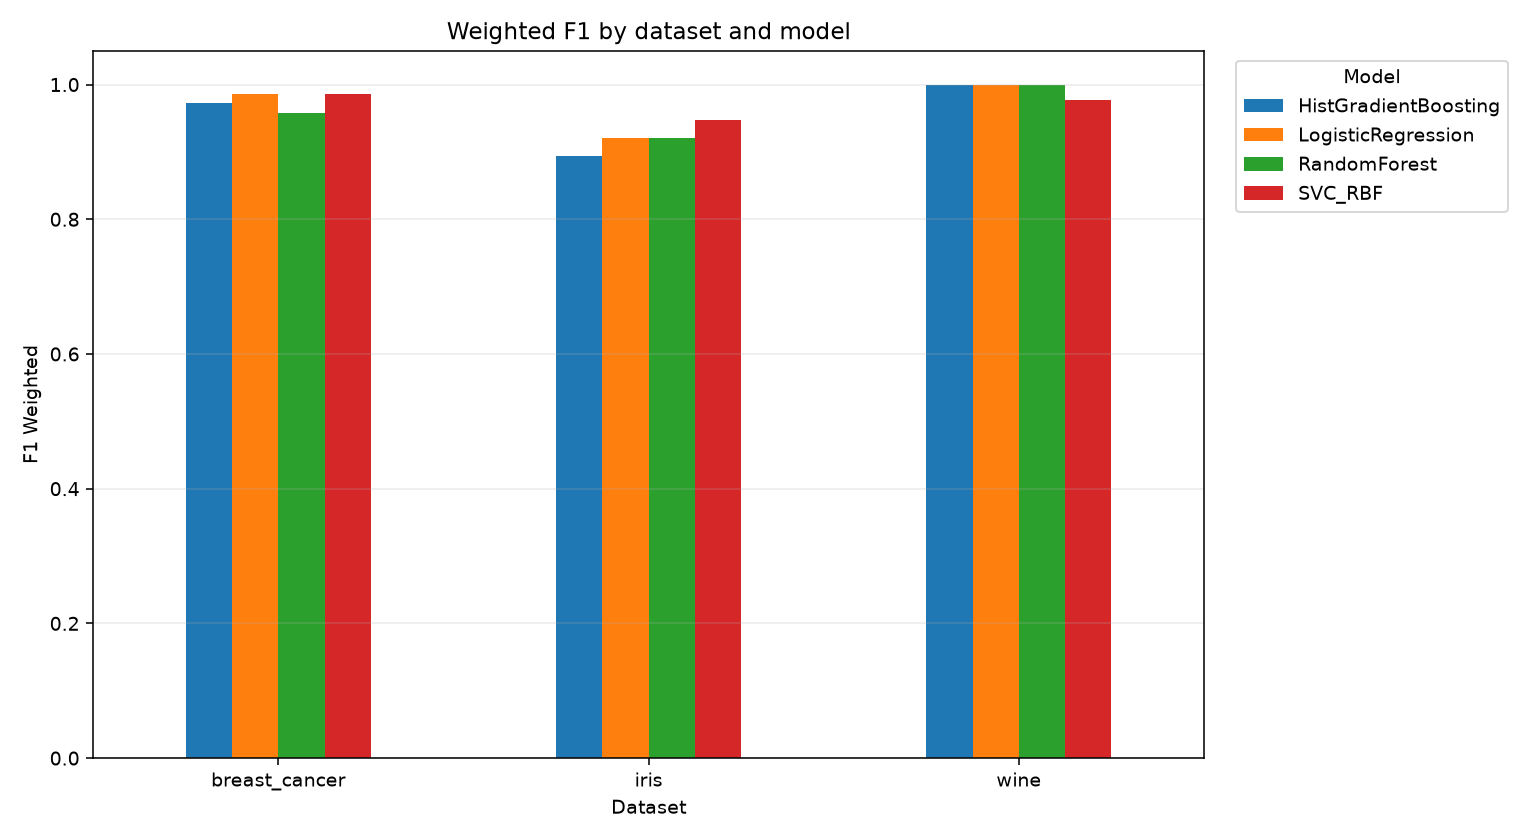

## Cross-validation accuracy comparison

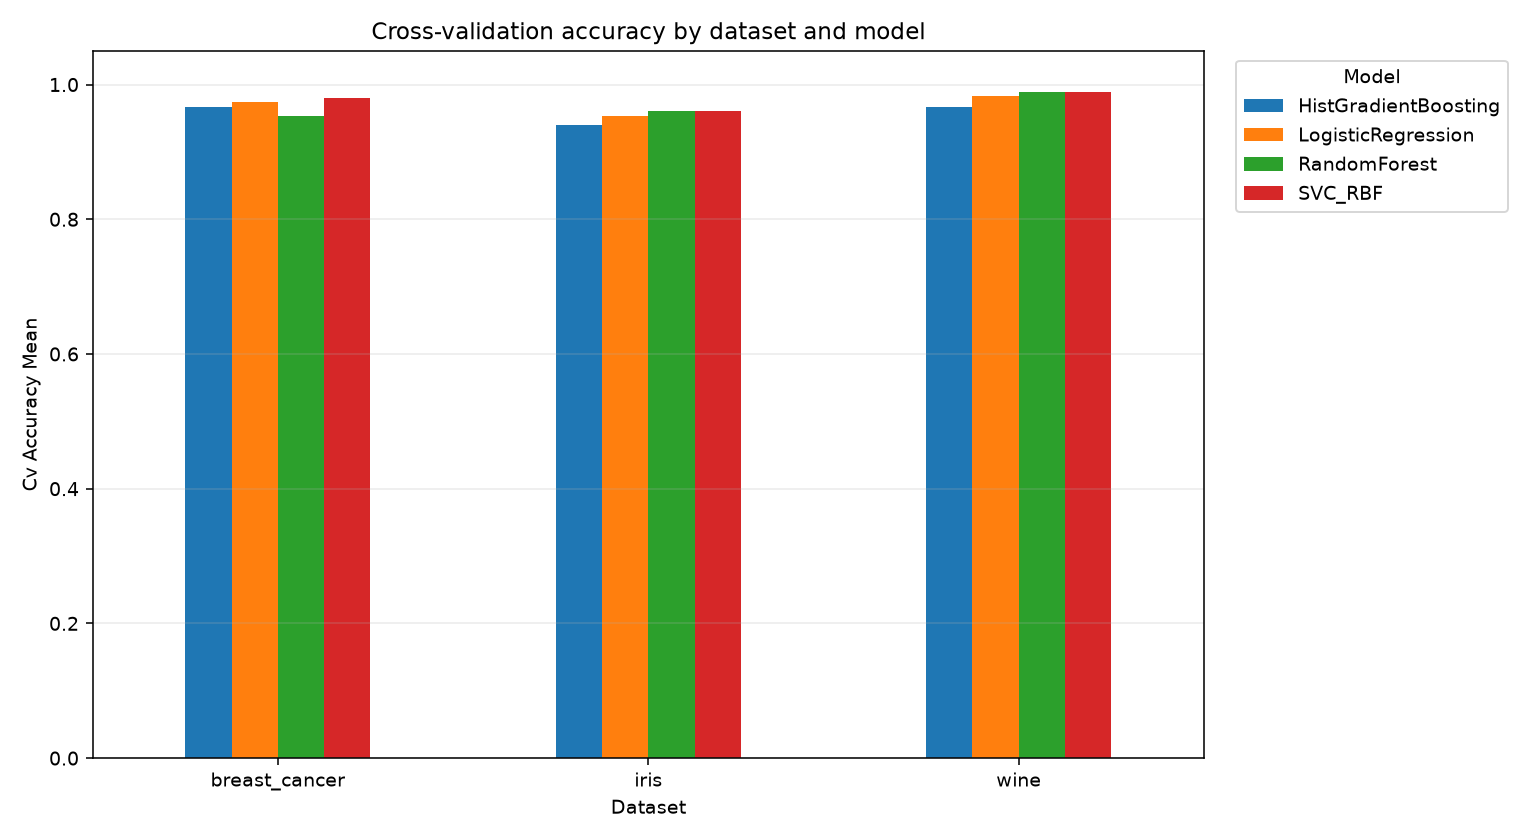

In [2]:
display(Markdown('## Weighted F1 comparison'))
display(Image(filename=str(OUT / 'f1_comparison.png')))
display(Markdown('## Cross-validation accuracy comparison'))
display(Image(filename=str(OUT / 'cv_accuracy_comparison.png')))

## Interpretation checklist

- Compare held-out weighted F1 and accuracy without treating small differences as conclusive.
- Use cross-validation mean and standard deviation to understand stability.
- Review fit and prediction time as well as predictive metrics.
- Inspect confusion matrices and class-level reports in `outputs/benchmark_details.json`.
- Results are demonstration benchmarks on small built-in datasets, not production performance claims.